# Logistic Regression

Muhammad Sarab Aftab

I am fitting logistic regression on the training split and checking it on dev. I am not using the test rows in this notebook.


## Loading the data

I am using the shared preparation file. It drops duplicate URLs, makes the split, and scales the numeric columns. I fit that on the training rows only, then transform dev.


In [1]:
from sklearn.linear_model import LogisticRegression

import warnings

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

from dataset_preparation import prepare_datasets

data = prepare_datasets()
pipeline = data["pipeline"]

X_train = pipeline.fit_transform(data["X_train"])
X_dev = pipeline.transform(data["X_dev"])
y_train = data["y_train"]
y_dev = data["y_dev"]

print("Train rows:", X_train.shape[0])
print("Dev rows:", X_dev.shape[0])
print("Features:", X_train.shape[1])
print("Test rows, not scored:", len(data["y_test"]))
print("Dev phishing rate:", round(float(y_dev.mean()), 4))


Train rows: 69138
Dev rows: 23046
Features: 22
Test rows, not scored: 23047
Dev phishing rate: 0.144


Dev is still about 14.4% phishing, so a model can look accurate and still miss a lot of phishing URLs. I am also looking at precision, recall, and F1 for phishing, plus ROC AUC.


## How I score it

Phishing is label 1. ROC AUC uses the predicted phishing probability.


In [2]:
def phishing_scores(model, X, y):
    predictions = model.predict(X)
    phishing_probability = model.predict_proba(X)[:, 1]

    return {
        "accuracy": accuracy_score(y, predictions),
        "precision": precision_score(y, predictions, pos_label=1, zero_division=0),
        "recall": recall_score(y, predictions, pos_label=1, zero_division=0),
        "f1": f1_score(y, predictions, pos_label=1, zero_division=0),
        "roc_auc": roc_auc_score(y, phishing_probability),
    }


## Fitting it

My settings are L2, C=1.0, the lbfgs solver, and no class weight.

A few of the scaled features are really extreme, so lbfgs prints overflow warnings while it searches. I hide those for the fit and the scores. The iteration count is just so I can see that it actually finished.


In [3]:
log_reg = LogisticRegression(
    penalty="l2",
    C=1.0,
    solver="lbfgs",
    class_weight=None,
    max_iter=1000,
    random_state=42,
)

with warnings.catch_warnings():
    warnings.filterwarnings("ignore", category=RuntimeWarning)
    log_reg.fit(X_train, y_train)
    print("Iterations:", int(log_reg.n_iter_[0]))
    scores = pd.DataFrame(
        {
            "train": phishing_scores(log_reg, X_train, y_train),
            "dev": phishing_scores(log_reg, X_dev, y_dev),
        }
    ).round(4)

scores


Iterations: 46


,train,dev
accuracy,0.9542,0.9530
precision,0.9026,0.9021
recall,0.7642,0.7556
f1,0.8277,0.8224
roc_auc,0.9753,0.9760


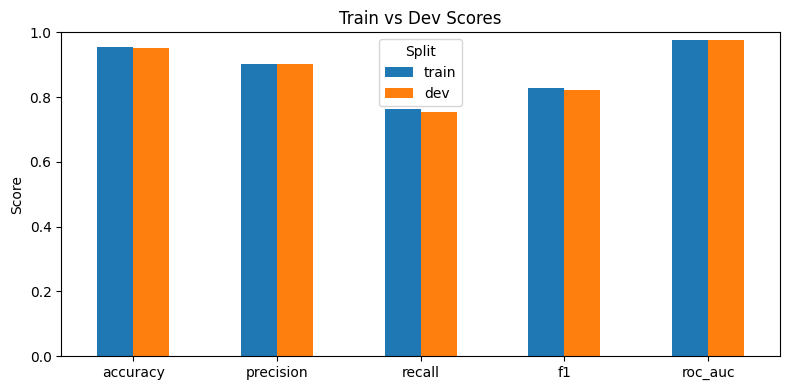

In [4]:
plt.figure(figsize=(8, 4))

scores.plot(kind="bar", ax=plt.gca())

plt.title("Train vs Dev Scores")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(title="Split")
plt.tight_layout()
plt.show()


## Conclusion

On dev this gets about 0.953 accuracy and a ROC AUC of about 0.976. Phishing precision is about 0.902, but recall is only about 0.756, so it misses a decent number of phishing URLs. Train and dev are really close, so this one looks pretty stable.

My decision tree does better on phishing recall and F1. This model still has the higher ROC AUC, so I would keep it around for the later comparison.
